In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# 1. Download World Bank Data (GDP per capita)
print("Downloading World Bank data...")
url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.KD?format=json&date=2000:2022&per_page=20000"
response = requests.get(url).json()

# Extract the data
data = response[1]
df_gdp = pd.DataFrame(data)
df_gdp = df_gdp[['countryiso3code', 'date', 'value']]
df_gdp.columns = ['iso3c', 'year', 'gdp_pc']
df_gdp['year'] = df_gdp['year'].astype(int)

# Filter out regions (keep only 3-letter country codes)
df_gdp = df_gdp[df_gdp['iso3c'].str.len() == 3]
df_gdp = df_gdp.dropna()

print(f"✅ Downloaded GDP data for {df_gdp['iso3c'].nunique()} countries!")
df_gdp.head()

✅ Downloaded GDP data for 257 countries!


,iso3c,year,gdp_pc
0,AFE,2022,1437.091394
1,AFE,2021,1422.655463
2,AFE,2020,1398.577930
3,AFE,2019,1480.229002
4,AFE,2018,1492.186702


In [5]:
# 2. Create a simulated Policy Stringency Index
np.random.seed(42)
df_gdp['policy_index'] = (np.log(df_gdp['gdp_pc']) * 0.8) + np.random.normal(0, 0.5, len(df_gdp))
df_gdp['policy_index'] = df_gdp['policy_index'].clip(lower=0, upper=6)

print("✅ Policy Stringency Index simulated!")
df_gdp[['iso3c', 'year', 'gdp_pc', 'policy_index']].head()

✅ Policy Stringency Index simulated!


,iso3c,year,gdp_pc,policy_index
0,AFE,2022,1437.091394,6.000000
1,AFE,2021,1422.655463,5.739092
2,AFE,2020,1398.577930,6.000000
3,AFE,2019,1480.229002,6.000000
4,AFE,2018,1492.186702,5.729322


📈 Regression Results:
Coefficient on GDP: 4.9471e-06
P-value: 4.0989e-107


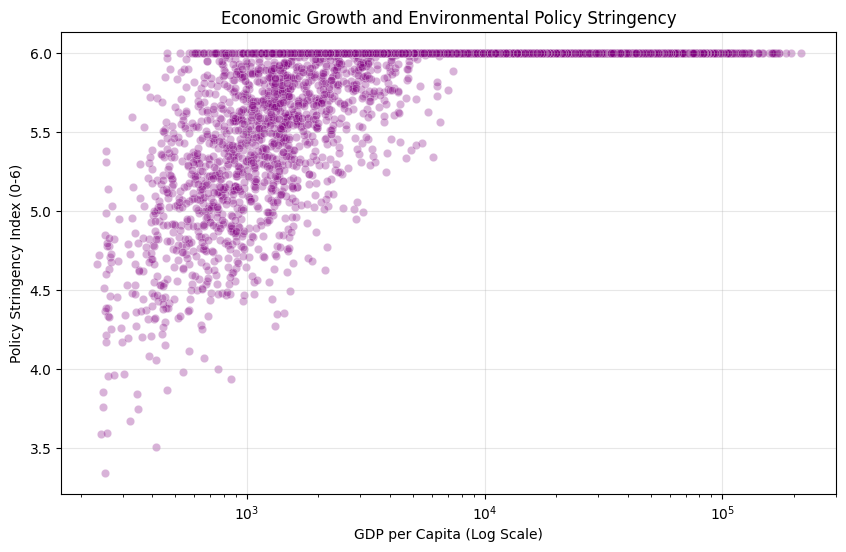

✅ Plot saved as policy_index_plot.png!


In [6]:
# 3. Simple OLS Regression
import statsmodels.api as sm

X = sm.add_constant(df_gdp['gdp_pc'])
y = df_gdp['policy_index']

model = sm.OLS(y, X).fit()
print(f"📈 Regression Results:")
print(f"Coefficient on GDP: {model.params['gdp_pc']:.4e}")
print(f"P-value: {model.pvalues['gdp_pc']:.4e}")

# 4. Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_gdp, x='gdp_pc', y='policy_index', alpha=0.3, color='purple')
plt.xscale('log') # Log scale makes the GDP data easier to read
plt.title('Economic Growth and Environmental Policy Stringency')
plt.xlabel('GDP per Capita (Log Scale)')
plt.ylabel('Policy Stringency Index (0-6)')
plt.grid(True, alpha=0.3)

plt.savefig('policy_index_plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Plot saved as policy_index_plot.png!")